In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data.csv")

print(df.head())
print("Shape:", df.shape)
df.info()

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
Shape: (891, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived

In [ ]:
print("Numerical Columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical Columns:")
print(df.select_dtypes(include=['object', 'bool']).columns.tolist())

print("\nStatistical Summary:")
display(df.describe())

Numerical Columns:
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

Categorical Columns:
['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Statistical Summary:


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
print(df.isnull().sum())

print("\nMissing Percentage:")
print((df.isnull().sum() / len(df)) * 100)

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           687
embark_town      2
alive            0
alone            0
dtype: int64

Missing Percentage:
survived        0.000000
pclass          0.000000
sex             0.000000
age            19.865320
sibsp           0.000000
parch           0.000000
fare            0.000000
embarked        0.224467
class           0.000000
who             0.000000
adult_male      0.000000
deck           77.104377
embark_town     0.224467
alive           0.000000
alone           0.000000
dtype: float64


In [ ]:
df_clean = df.copy()

# Remove columns with excessive missing values
df_clean.drop(
    columns=['deck', 'class', 'embark_town',
             'alive', 'adult_male'],
    inplace=True
)

# Fill Age using median
df_clean['age'] = df_clean['age'].fillna(
    df_clean['age'].median()
)

# Fill Embarked using mode
df_clean['embarked'] = df_clean['embarked'].fillna(
    df_clean['embarked'].mode()[0]
)

print(df_clean.isnull().sum())

survived    0
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
who         0
alone       0
dtype: int64


In [ ]:
print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 116


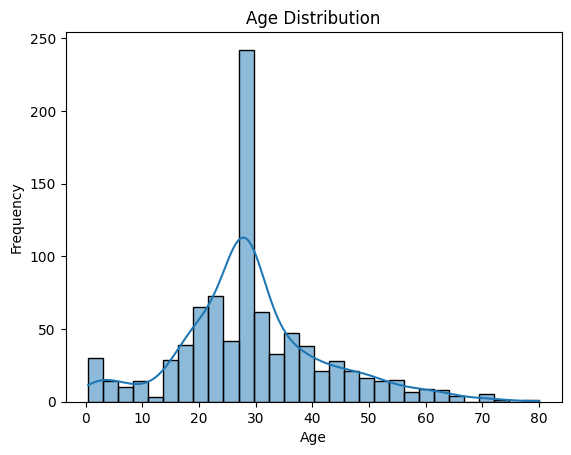

In [ ]:
sns.histplot(df_clean['age'], kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

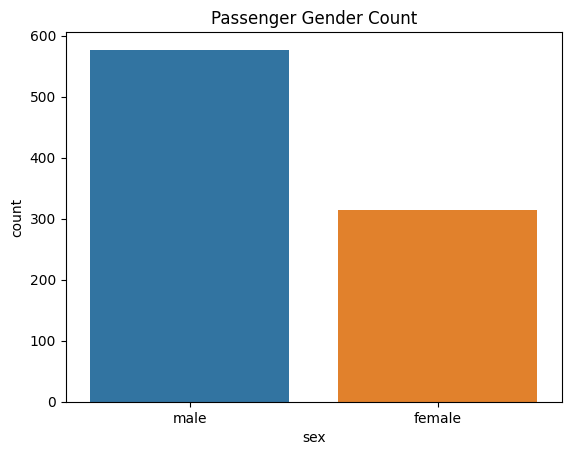

In [ ]:
sns.countplot(data=df_clean, x='sex', hue='sex', legend=False)
plt.title("Passenger Gender Count")
plt.show()

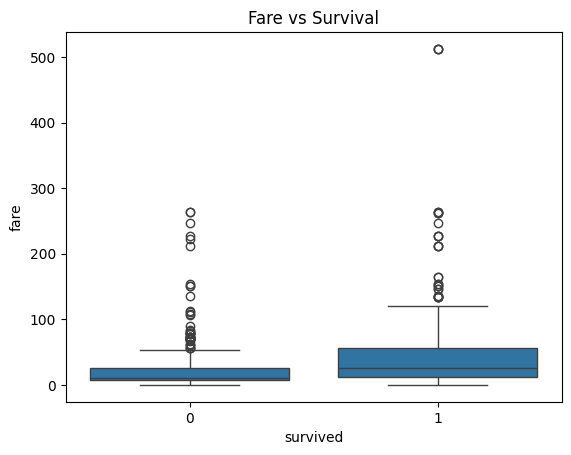

In [ ]:
sns.boxplot(data=df_clean, x='survived', y='fare')
plt.title("Fare vs Survival")
plt.show()

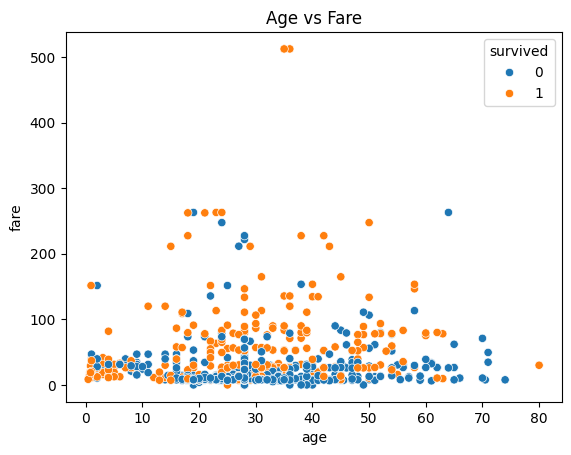

In [ ]:
sns.scatterplot(
    data=df_clean,
    x='age',
    y='fare',
    hue='survived'
)
plt.title("Age vs Fare")
plt.show()

In [ ]:
df_encoded = pd.get_dummies(
    df_clean,
    columns=['sex', 'embarked', 'who', 'alone'],
    dtype=int
)

display(df_encoded.head())

,survived,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S,who_child,who_man,who_woman,alone_False,alone_True
0,0,3,22.0,1,0,7.2500,0,1,0,0,1,0,1,0,1,0
1,1,1,38.0,1,0,71.2833,1,0,1,0,0,0,0,1,1,0
2,1,3,26.0,0,0,7.9250,1,0,0,0,1,0,0,1,0,1
3,1,1,35.0,1,0,53.1000,1,0,0,0,1,0,0,1,1,0
4,0,3,35.0,0,0,8.0500,0,1,0,0,1,0,1,0,0,1


In [ ]:
from sklearn.preprocessing import StandardScaler

columns = ['pclass', 'age', 'sibsp', 'parch', 'fare']

scaler = StandardScaler()

df_encoded[columns] = scaler.fit_transform(
    df_encoded[columns]
)

display(df_encoded.head())

,survived,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S,who_child,who_man,who_woman,alone_False,alone_True
0,0,0.827377,-0.565736,0.432793,-0.473674,-0.502445,0,1,0,0,1,0,1,0,1,0
1,1,-1.566107,0.663861,0.432793,-0.473674,0.786845,1,0,1,0,0,0,0,1,1,0
2,1,0.827377,-0.258337,-0.474545,-0.473674,-0.488854,1,0,0,0,1,0,0,1,0,1
3,1,-1.566107,0.433312,0.432793,-0.473674,0.420730,1,0,0,0,1,0,0,1,1,0
4,0,0.827377,0.433312,-0.474545,-0.473674,-0.486337,0,1,0,0,1,0,1,0,0,1


In [ ]:
print("Final Shape:", df_encoded.shape)
print("Missing Values:", df_encoded.isnull().sum().sum())
print("Duplicate Rows:", df_encoded.duplicated().sum())

Final Shape: (891, 16)
Missing Values: 0
Duplicate Rows: 116


In [ ]:
df_encoded.to_csv(
    'data_prepared.csv',
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!
